In [1]:
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

import numpy as np
import matplotlib.pyplot as plt
from gwpy.timeseries import TimeSeries
from matplotlib.colors import Normalize
from gwtorch.modules.gw_utils import generate_prior, generate_waveform, display_qtransform, pad_to_shape

In [2]:
sample = generate_prior(3)

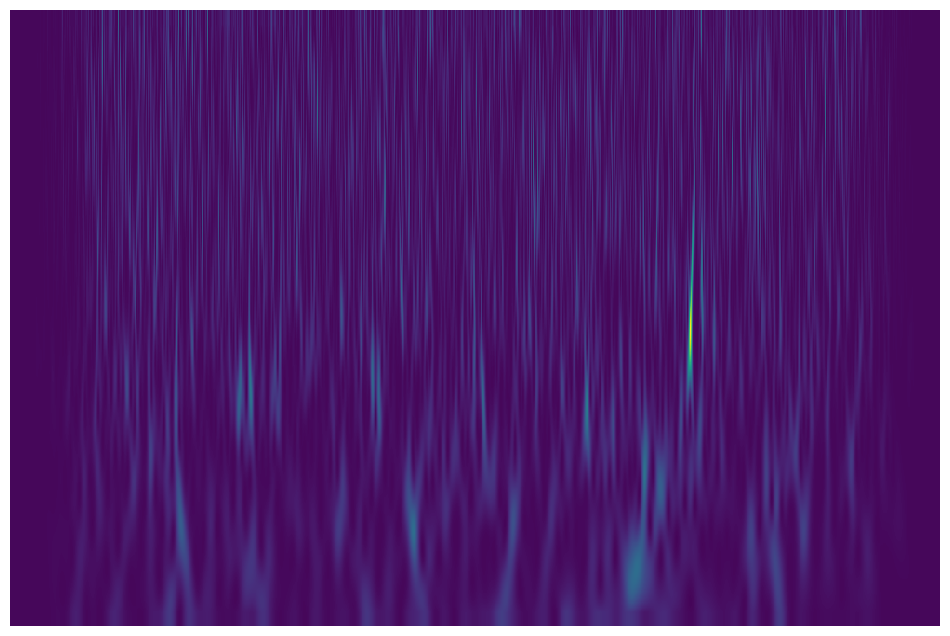

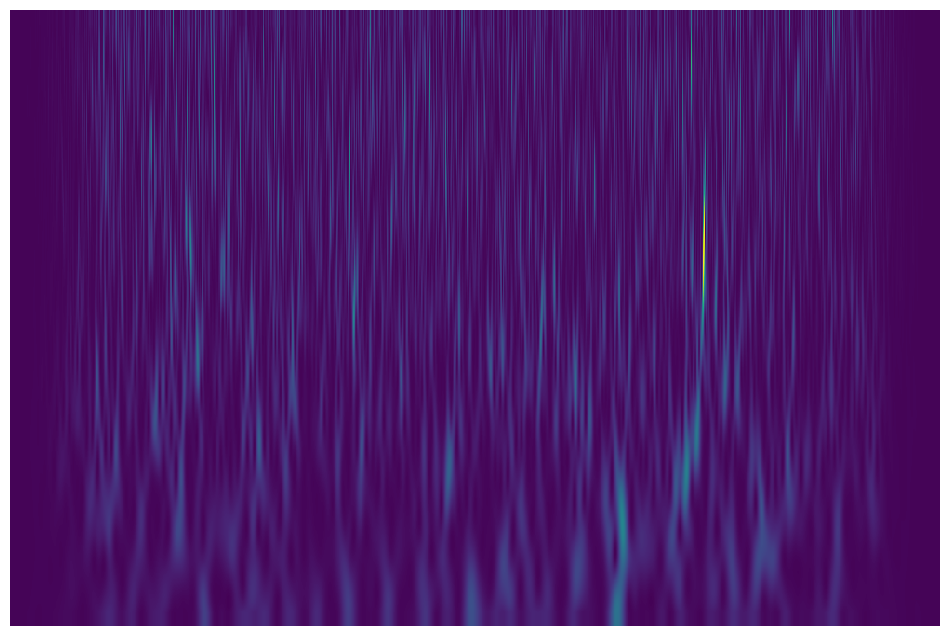

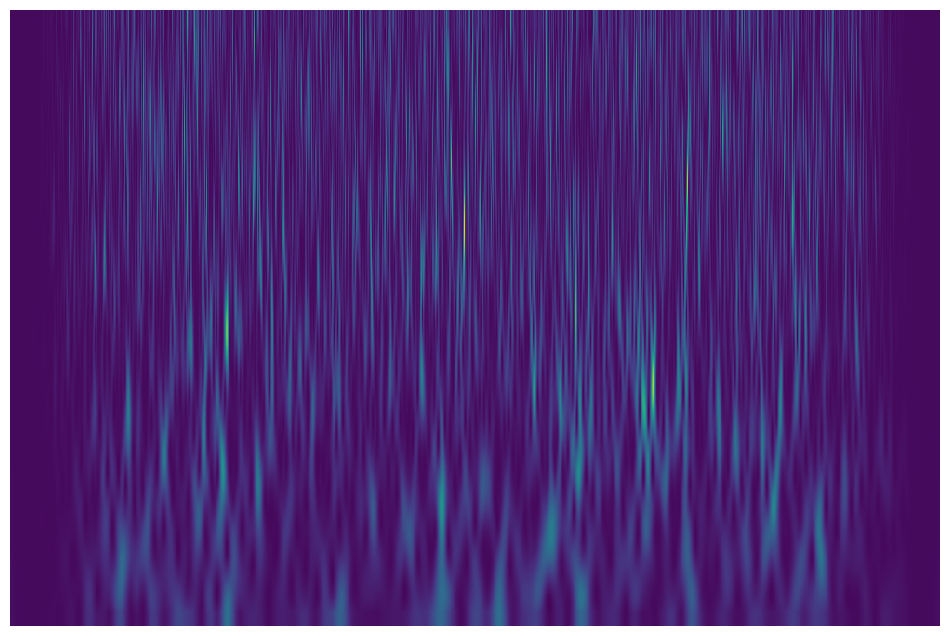

In [22]:
stacked_q = []
for i in range(len(sample)):
    ecc_dict, lens_dict, unlens_dict, mass1, mass2, m_lens, y_lens = generate_waveform(0, sample[i], display=False)
    ecc = ecc_dict['ecc_signal']
    qt = display_qtransform(ecc)
    stacked_q.append(np.abs(qt.data).T)

In [24]:
max_shape = (
    max(q.shape[0] for q in stacked_q),
    max(q.shape[1] for q in stacked_q)
)

padded_q = [pad_to_shape(q, max_shape) for q in stacked_q]
normed = [Normalize()(q) for q in padded_q]

stacked = np.stack(normed, axis=0)
stacked_img = np.transpose(stacked, (1, 2, 0))

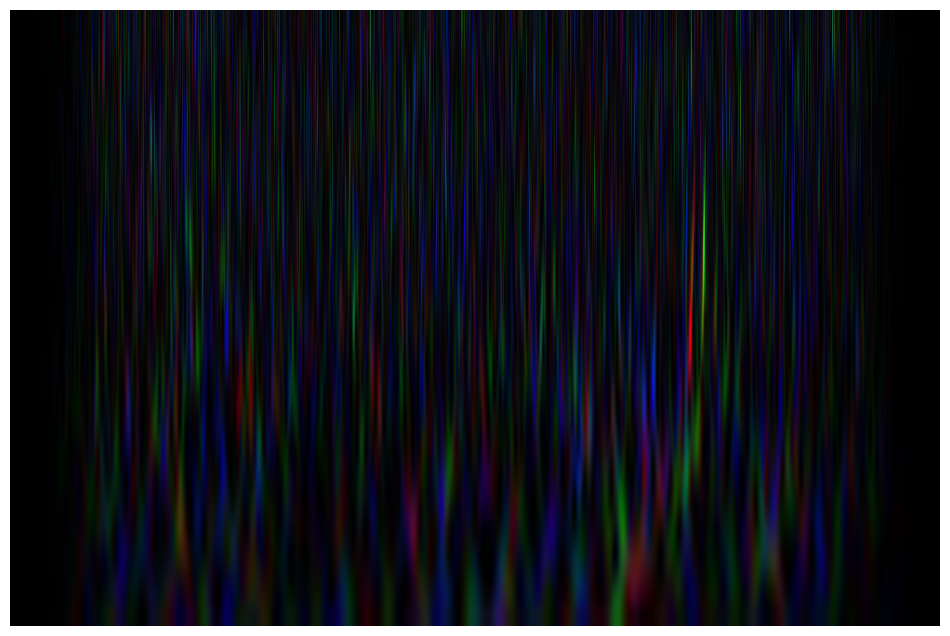

In [25]:
plt.figure(figsize=(12, 8), frameon=False)
plt.imshow(stacked_img, aspect='auto', origin='lower')
plt.grid('off')
plt.axis('off')
plt.show()